# Week 4b — State Source Expansion: JalanJalanMY

**Upload to Colab:** `MTG_2023.pdf`, `Map_Guide_PENANG_Eng.pdf`, `Melaka_Map_Guide_IDB_small.pdf`, `Sabah Map & Guide.pdf`, and `data/prepared_chunks_clean.jsonl` from the repo. Then use Runtime → Run all.

> The source PDFs are © Tourism Malaysia (all rights reserved).

## 1 — Setup and source check

In [ ]:
!pip install -q pypdf pandera langchain-core matplotlib
import os, re, json, shutil, pickle, hashlib
from pathlib import Path
from datetime import date
import pandas as pd

BASE = Path('/content')
RAW = BASE / 'states_raw'; RAW.mkdir(exist_ok=True)
(BASE / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
(BASE / 'docs').mkdir(exist_ok=True)

NEEDED = ['MTG_2023.pdf', 'Map_Guide_PENANG_Eng.pdf', 'Melaka_Map_Guide_IDB_small.pdf', 'Sabah Map & Guide.pdf']
for name in NEEDED:                                    # move uploads from /content into states_raw
    if (BASE / name).is_file() and not (RAW / name).is_file():
        shutil.move(str(BASE / name), str(RAW / name))
missing = [n for n in NEEDED if not (RAW / n).is_file()]
assert not missing, f'Upload these PDFs first: {missing}'
KL_CLEAN = BASE / 'prepared_chunks_clean_v2.jsonl'
if not KL_CLEAN.exists() and (BASE / 'data' / 'prepared_chunks_clean_v2.jsonl').exists():
    shutil.copy(BASE / 'data' / 'prepared_chunks_clean_v2.jsonl', KL_CLEAN)
assert KL_CLEAN.exists(), 'Upload data/prepared_chunks_clean.jsonl (Topic 4 reviewed KL corpus) first.'
print('All inputs present:', NEEDED + [KL_CLEAN.name])


All inputs present: ['MTG_2023.pdf', 'Map_Guide_PENANG_Eng.pdf', 'Melaka_Map_Guide_IDB_small.pdf', 'Sabah Map & Guide.pdf', 'prepared_chunks_clean_v2.jsonl']


In [ ]:
# Shared preparation logic for the state-source expansion (same methods as Topic 3 / Topic 4).
# Usage: python3 -I prep_lib.py <src_dir> <out_jsonl>   (exploration run)
import re, json, hashlib, sys
from pathlib import Path
from pypdf import PdfReader

import pypdf
try:
    pypdf.overwrite_configuration(stream_parsing_work_maximum_count=50_000_000)
except AttributeError:
    pass  # older pypdf has no limit, nothing to change

SOURCES = [  # (source_id, file, state, first_page, last_page, kind)
    ("S03", "MTG_2023.pdf", "Melaka", 53, 63, "guide-chapter"),
    ("S04", "MTG_2023.pdf", "Penang", 89, 99, "guide-chapter"),
    ("S05", "MTG_2023.pdf", "Sabah", 159, 179, "guide-chapter"),
    ("S06", "Map_Guide_PENANG_Eng.pdf", "Penang", 1, 2, "map-guide"),
    ("S07", "Melaka_Map_Guide_IDB_small.pdf", "Melaka", 1, 2, "map-guide"),
    ("S08", "Sabah Map & Guide.pdf", "Sabah", 1, 2, "map-guide"),
]
PHONE = re.compile(r'\+?6?0\d[\d\s-]{6,}')

def keep_line(line):
    """Map-label filter: keep sentence lines, phone lines and long upper-case headings."""
    l = line.strip()
    words = re.findall(r"[A-Za-z']+", l)
    return len(words) >= 4 or bool(PHONE.search(l)) or (len(words) >= 2 and l.isupper() and len(l) >= 8)

def fixed_chunks(s, size=500):          # Topic 3, unchanged
    if size <= 0:
        raise ValueError("Chunk size must be positive")
    return [s[i:i + size] for i in range(0, len(s), size)]

def paragraph_chunks(s, size=500):      # Topic 3, unchanged
    if size <= 0:
        raise ValueError("Chunk size must be positive")
    parts, current = [], ""
    for segment in re.split(r"\n\s*\n", s):
        segment = segment.strip()
        if not segment:
            continue
        if len(segment) > size:
            if current:
                parts.append(current); current = ""
            parts.extend(fixed_chunks(segment, size))
        elif len(current) + len(segment) + (2 if current else 0) <= size:
            current += ("\n\n" if current else "") + segment
        else:
            if current:
                parts.append(current)
            current = segment
    if current:
        parts.append(current)
    return parts

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def prepare(src_dir):
    src_dir = Path(src_dir); records, stats = [], []
    for sid, fname, state, a, b, kind in SOURCES:
        path = src_dir / fname; reader = PdfReader(str(path)); digest = sha256(path)
        n_lines = n_kept = 0; chars = 0
        for p in range(a, b + 1):
            text = reader.pages[p - 1].extract_text() or ""
            chars += len(text)
            if kind == "map-guide":
                lines = [l for l in text.splitlines() if l.strip()]
                kept = [l for l in lines if keep_line(l)]
                n_lines += len(lines); n_kept += len(kept)
                text = "\n".join(kept)
            clean = re.sub(r"[ \t]+", " ", text).strip()
            for n, chunk in enumerate(paragraph_chunks(clean, 500)):
                records.append({
                    "record_id": f"{sid}-p{p}-{n:03d}", "text": chunk, "source": fname,
                    "source_id": sid, "state": state, "page": p, "source_sha256": digest,
                    "processing": "paragraph-aware-char-500" + ("+map-label-filter" if kind == "map-guide" else ""),
                })
        stats.append({"source_id": sid, "file": fname, "state": state, "pages": f"{a}-{b}", "kind": kind,
                      "extracted_chars": chars, "map_lines": n_lines, "map_lines_kept": n_kept,
                      "chunks": sum(1 for r in records if r["source_id"] == sid)})
    return records, stats

# Source inspection: pages, readable text, glyph-ID and ligature artefacts, PDF dates
from pypdf import PdfReader
inspect_rows = []
for sid, fname, state, a, b, kind in SOURCES:
    reader = PdfReader(str(RAW / fname))
    text = '\n'.join(reader.pages[p - 1].extract_text() or '' for p in range(a, b + 1))
    meta = reader.metadata or {}
    inspect_rows.append({'source_id': sid, 'file': fname, 'state': state, 'pages': f'{a}-{b}', 'kind': kind,
                         'chars': len(text), 'glyph_id_codes': len(re.findall(r'/gid\d{5}', text)),
                         'ligature_artefacts': len(re.findall(r'/f_|[ﬀ-ﬆ]', text)),
                         'pdf_modified': str(meta.get('/ModDate', ''))[2:10],
                         'sha256': sha256(RAW / fname)[:12]})
inspection = pd.DataFrame(inspect_rows)
print(inspection.to_string(index=False))


source_id                           file  state   pages          kind  chars  glyph_id_codes  ligature_artefacts pdf_modified       sha256
      S03                   MTG_2023.pdf Melaka   53-63 guide-chapter  15617               0                   0     20250528 7b1830e31301
      S04                   MTG_2023.pdf Penang   89-99 guide-chapter  17573               0                   0     20250528 7b1830e31301
      S05                   MTG_2023.pdf  Sabah 159-179 guide-chapter  21164               0                   1     20250528 7b1830e31301
      S06       Map_Guide_PENANG_Eng.pdf Penang     1-2     map-guide  39435               0                   6     20240314 1f956c184ebb
      S07 Melaka_Map_Guide_IDB_small.pdf Melaka     1-2     map-guide  30276               0                   1     20240208 253d2ec35fd8
      S08          Sabah Map & Guide.pdf  Sabah     1-2     map-guide  33056               0                   8     20240221 f90bfc87175d


**Inspection findings:**
- **Guide chapters (S03–S05):** readable prose, one page each, no glyph-ID text. Pages 53–63 (Melaka), 89–99 (Penang) and 159–179 (Sabah) were chosen because each starts with the state's title page.
- **Map guides (S06–S08):** readable descriptions mixed with map labels (street names such as *Jalan Argyll*, area names such as *Taman*, *Wisma*), as already seen for Penang in Topic 3.

**Map-label filter (added cleaning step for S06–S08):** keep a line only if it has **≥ 4 words**, contains a **phone number**, or is an **upper-case heading of ≥ 8 characters** (attraction names such as `BASTION MIDDLEBURG`).

## 2 — Topic 3 steps: extract, filter, chunk (page numbers kept)

In [ ]:
records, stats = prepare(RAW)
stats_df = pd.DataFrame(stats)
print(stats_df.to_string(index=False))
print('\nNew prepared records:', len(records))

# Show what the filter removes and keeps (Penang map guide, S06)
reader = PdfReader(str(RAW / 'Map_Guide_PENANG_Eng.pdf'))
lines = [l.strip() for l in (reader.pages[0].extract_text() or '').splitlines() if l.strip()]
print('\nDropped examples:', [l for l in lines if not keep_line(l)][100:110])
print('Kept examples   :', [l for l in lines if keep_line(l)][200:205])

prepared_states = BASE / 'data' / 'processed' / 'prepared_text_states.jsonl'
with prepared_states.open('w', encoding='utf-8') as f:
    for r in records:
        f.write(json.dumps(r, ensure_ascii=False) + '\n')
print('\nSaved', prepared_states, prepared_states.stat().st_size, 'bytes')


source_id                           file  state   pages          kind  extracted_chars  map_lines  map_lines_kept  chunks
      S03                   MTG_2023.pdf Melaka   53-63 guide-chapter            15607          0               0      35
      S04                   MTG_2023.pdf Penang   89-99 guide-chapter            17563          0               0      40
      S05                   MTG_2023.pdf  Sabah 159-179 guide-chapter            21144          0               0      54
      S06       Map_Guide_PENANG_Eng.pdf Penang     1-2     map-guide            39434       1757             598      53
      S07 Melaka_Map_Guide_IDB_small.pdf Melaka     1-2     map-guide            30275       1310             447      42
      S08          Sabah Map & Guide.pdf  Sabah     1-2     map-guide            33055       1289             474      46

New prepared records: 270

Dropped examples: ['Jalan Argyll', 'Lengkok Pengkalan Weld', 'Jalan Sungai Pinang', 'Jalan Logan', 'Jalan Anson', 'Leb

## 3 — Topic 4 checks on the new chunks (same rules)

In [ ]:
import pandera.pandas as pa

APPROVED = {fname: state for _, fname, state, *_ in SOURCES}
MODIFIED = {'MTG_2023.pdf': date(2025, 5, 28), 'Map_Guide_PENANG_Eng.pdf': date(2024, 3, 14),
            'Melaka_Map_Guide_IDB_small.pdf': date(2024, 2, 8), 'Sabah Map & Guide.pdf': date(2024, 2, 21)}
LIGATURE = re.compile(r'/f_|[ﬀ-ﬆ]')
HOURS = re.compile(r'(?i)opening hours|\d{1,2}[.:]\d{2}\s?(?:am|pm)|\b\d{1,2}\s?(?:am|pm)\b')
PRICE = re.compile(r'RM ?\d')
months = lambda d: (date.today().year - d.year) * 12 + (date.today().month - d.month)

df = pd.DataFrame([{
    'chunk_id': i, 'record_id': r['record_id'], 'source': r['source'], 'state': r['state'], 'page': r['page'],
    'text': r['text'], 'char_count': len(r['text'].strip()),
    'has_bad_char': ('\x00' in r['text']) or ('�' in r['text']),
    'has_ligature_artefact': bool(LIGATURE.search(r['text'])),
    'glyph_id_garbage': bool(re.search(r'/gid\d{5}', r['text'])),
    'has_page_ref': r['page'] is not None,
    'source_age_months': months(MODIFIED[r['source']]),
    'has_hours': bool(HOURS.search(r['text'])), 'has_price': bool(PRICE.search(r['text'])),
} for i, r in enumerate(records)])

schema = pa.DataFrameSchema({
    'source': pa.Column(str, checks=pa.Check.isin(list(APPROVED), error='source not in approved inventory')),
    'text': pa.Column(str, checks=pa.Check(lambda s: s.str.strip().str.len() > 0, error='chunk text must not be empty')),
    'char_count': pa.Column(int, checks=pa.Check.ge(100, error='char_count >= 100 (shorter than one sentence)')),
    'has_bad_char': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='garbled/replacement characters found')),
    'has_ligature_artefact': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='PDF ligature artefact (/f_ or U+FB00-FB06)')),
    'glyph_id_garbage': pa.Column(bool, checks=pa.Check(lambda s: ~s, error='glyph-ID garbage (/gidNNNNN): unreadable map text')),
    'has_page_ref': pa.Column(bool, checks=pa.Check(lambda s: s, error='page reference missing (traceability)')),
    'source_age_months': pa.Column(int, checks=pa.Check.le(36, error='source older than 36 months')),
}, strict=False)

try:
    schema.validate(df, lazy=True); failures = pd.DataFrame()
except pa.errors.SchemaErrors as exc:
    failures = exc.failure_cases.copy()
failures.to_csv(BASE / 'docs' / 'week4_states_validation_failures.csv', index=False)
print('Failures by rule:')
print(failures['check'].value_counts().to_string() if not failures.empty else 'none')
print('\nSource age (months):', df.groupby('source')['source_age_months'].first().to_dict())
for _, row in df[df['char_count'] < 100].iterrows():
    print(f"SHORT {row['record_id']:14} {row['char_count']:3} chars: {row['text'].strip()!r}")


Failures by rule:
check
char_count >= 100 (shorter than one sentence)    12
PDF ligature artefact (/f_ or U+FB00-FB06)        5

Source age (months): {'MTG_2023.pdf': 18, 'Map_Guide_PENANG_Eng.pdf': 32, 'Melaka_Map_Guide_IDB_small.pdf': 33, 'Sabah Map & Guide.pdf': 33}
SHORT S03-p60-003      1 chars: 'f'
SHORT S04-p90-000     30 chars: '90\n| PENANG\nPlaces of Interest'
SHORT S04-p93-002     21 chars: 'ghill\n@mypenanghill\nf'
SHORT S04-p97-005     23 chars: '• Church of St. Anthony'
SHORT S05-p159-002    48 chars: 'SARAWAK\nLABUAN\nSarawak Cultural Village, Sarawak'
SHORT S05-p160-000    27 chars: '160 | SABAH\n| Sibuan Island'
SHORT S05-p162-001     3 chars: 'rks'
SHORT S05-p163-001    45 chars: 'Manukan. \nwww.sabahparks.org.my \n@sabahparksf'
SHORT S05-p165-000    10 chars: '165SABAH |'
SHORT S05-p169-002    83 chars: 'can be arranged. \nwww.sabahtourism.com\n@cocoavillagetawau\n@tawauteckguanlet’splay\nf'
SHORT S05-p171-001    88 chars: 'he once lived. \nwww.monsopiad.com\n@Monsop

**Rule note:** the age limit is **36 months** here because the map guides are dated early 2024. This is recorded as a deliberate change; the 24-month warning would flag all three map guides.

### Triage of the short chunks
| Chunks | Evidence | Decision |
|---|---|---|
| `S03-p60-003` (`f`), `S05-p162-001` (`rks`), `S04-p93-002` (social-media handle fragment) | End-of-page fragments | **Remove** — no usable content |
| `S04-p90-000`, `S05-p160-000`, `S05-p165-000`, `S05-p173-000` | Page headers such as `165SABAH |` and `90 | PENANG Places of Interest` | **Remove** — page furniture |
| `S05-p159-002` | Photo captions naming **Sarawak** and **Labuan** on the Sabah title page | **Remove** — not Sabah content |
| `S04-p97-005` (`• Church of St. Anthony`) | A real attraction name from a list | **Retain** |
| `S05-p163-001`, `S05-p169-002`, `S05-p171-001` | Sentence endings plus **official website** links (sabahparks.org.my, monsopiad.com) | **Retain** — useful source links |
| `S07-p1-014` | Phone-number tail, "Tourist Information Centres (TIC)", map title | **Retain (review)** — low value |
| Ligature chunks | Same deterministic defect as Topic 4 | **Correct** |

In [ ]:
import unicodedata
from langchain_core.documents import Document

REMOVE = {
    'S03-p60-003': 'removed: end-of-page fragment', 'S05-p162-001': 'removed: end-of-page fragment',
    'S04-p93-002': 'removed: social-media handle fragment',
    'S04-p90-000': 'removed: page header', 'S05-p160-000': 'removed: page header',
    'S05-p165-000': 'removed: page header', 'S05-p173-000': 'removed: page header',
    'S05-p159-002': 'removed: captions about Sarawak/Labuan, not Sabah content',
}
def repair_ligatures(text):
    text = text.replace('/f_', 'f')
    return re.sub(r'[ﬀ-ﬆ]', lambda m: unicodedata.normalize('NFKC', m.group(0)), text)

new_docs, removed, repaired_n = [], [], 0
for r in records:
    if r['record_id'] in REMOVE:
        removed.append({'record_id': r['record_id'], 'decision': 'removed', 'reason': REMOVE[r['record_id']],
                        'preview': re.sub(r'\s+', ' ', r['text'])[:160]}); continue
    if r['record_id'] not in set(df['record_id']):
        continue
    text = repair_ligatures(r['text']); repaired_n += text != r['text']
    meta = {k: r[k] for k in ('source', 'source_id', 'state', 'page', 'record_id', 'source_sha256', 'processing')}
    meta['topic4_ligatures_repaired'] = text != r['text']
    new_docs.append(Document(page_content=text, metadata=meta))
assert len(removed) == len(REMOVE), 'A REMOVE id was not found'
pd.DataFrame(removed).to_csv(BASE / 'docs' / 'week4_states_quarantine_log.csv', index=False)
print('Removed:', len(removed), '| ligature-repaired:', repaired_n, '| new chunks kept:', len(new_docs))
print('Ligatures left:', sum(bool(LIGATURE.search(d.page_content)) for d in new_docs))


Removed: 8 | ligature-repaired: 5 | new chunks kept: 262
Ligatures left: 0


## 4 — Merge with the reviewed KL corpus → corpus v2

In [ ]:
kl_records = [json.loads(l) for l in KL_CLEAN.open(encoding='utf-8') if l.strip()]
kl_docs = []
for r in kl_records:
    meta = dict(r['metadata']); meta.setdefault('state', 'Kuala Lumpur'); meta.setdefault('source_id', 'S01')
    kl_docs.append(Document(page_content=r['text'], metadata=meta))
print('KL reviewed chunks (Topic 4):', len(kl_docs))

all_docs = kl_docs + new_docs
seen, unique_docs, dup_rows = {}, [], []
for d in all_docs:
    h = hashlib.sha256(re.sub(r'\s+', ' ', d.page_content.strip()).encode('utf-8')).hexdigest()
    if h in seen:
        dup_rows.append({'hash': h, 'duplicate_source': d.metadata['record_id'], 'first_source': seen[h],
                         'preview': d.page_content[:160]}); continue
    seen[h] = d.metadata['record_id']; unique_docs.append(d)
print('Before dedup:', len(all_docs), '| after:', len(unique_docs), '| exact duplicates:', len(dup_rows))

def trigrams(t):
    w = re.findall(r'\w+', t.lower()); return set(zip(w, w[1:], w[2:]))
G = [trigrams(d.page_content) for d in unique_docs]
near = [(unique_docs[i].metadata['record_id'], unique_docs[j].metadata['record_id'], round(len(G[i] & G[j]) / len(G[i] | G[j]), 2))
        for i in range(len(G)) for j in range(i + 1, len(G))
        if G[i] and G[j] and len(G[i] & G[j]) / len(G[i] | G[j]) >= 0.5]
print('Near-duplicate pairs (trigram Jaccard >= 0.5):', len(near))
for a, b, j in near:
    print(f'  {a} vs {b}: {j}')

# Near-duplicate decisions (reviewed by reading each pair; see table below)
NEAR_DUP = {
    'S06-p2-008': ('remove', 'S04-p96-002', 'same Habitat Penang Hill text as the 2025 guide chapter; adds nothing'),
    'S08-p2-012': ('remove', 'S05-p168-000', 'same Mari Mari Cultural Village text as the guide chapter; adds nothing'),
    'S08-p2-004': ('remove', 'S05-p179-000', 'same Sabah transport text as the guide chapter; adds nothing'),
    'S06-p2-020': ('remove', '-', 'generic "About Malaysia" introduction repeated in every map guide; not state content'),
    'S07-p2-001': ('remove', '-', 'generic "About Malaysia" introduction repeated in every map guide; not state content'),
    'S08-p2-002': ('remove', '-', 'generic "About Malaysia" introduction repeated in every map guide; not state content'),
    'S07-p2-011': ('retain-tagged', 'S03-p56-000', 'same Encore Melaka text but adds a phone number'),
    'S06-p2-002': ('retain-tagged', 'S04-p95-000', 'same Batu Ferringhi text but adds a phone number'),
}
flagged = {x for a, b, _ in near for x in (a, b)}
assert set(NEAR_DUP) <= flagged, 'A near-duplicate decision refers to a chunk that was not flagged'
for d in unique_docs:
    rid = d.metadata['record_id']
    if rid in NEAR_DUP and NEAR_DUP[rid][0] == 'retain-tagged':
        d.metadata['near_duplicate_of'] = NEAR_DUP[rid][1]
for rid, (decision, other, reason) in NEAR_DUP.items():
    doc = next(d for d in unique_docs if d.metadata['record_id'] == rid)
    dup_rows.append({'hash': 'near-duplicate', 'duplicate_source': rid, 'first_source': other,
                     'preview': f'{decision}: {reason} | ' + re.sub(r'\s+', ' ', doc.page_content)[:120]})
unique_docs = [d for d in unique_docs if NEAR_DUP.get(d.metadata['record_id'], ('keep',))[0] != 'remove']
print('Near-duplicates removed:', sum(v[0] == 'remove' for v in NEAR_DUP.values()),
      '| retained with near_duplicate_of tag:', sum(v[0] == 'retain-tagged' for v in NEAR_DUP.values()))
pd.DataFrame(dup_rows, columns=['hash', 'duplicate_source', 'first_source', 'preview']).to_csv(
    BASE / 'docs' / 'week4_states_duplicate_review.csv', index=False)

with open(BASE / 'data' / 'chunks_clean_v2.pkl', 'wb') as f:
    pickle.dump(unique_docs, f)
with open(BASE / 'data' / 'prepared_chunks_clean_v2.jsonl', 'w', encoding='utf-8') as f:
    for i, d in enumerate(unique_docs):
        f.write(json.dumps({'chunk_id': i, 'text': d.page_content, 'metadata': d.metadata}, ensure_ascii=False) + '\n')
print('Saved corpus v2:', len(unique_docs), 'chunks')


KL reviewed chunks (Topic 4): 503
Before dedup: 765 | after: 577 | exact duplicates: 188
Near-duplicate pairs (trigram Jaccard >= 0.5): 77
  S03-p56-000 vs S07-p2-011: 0.65
  S03-p58-002 vs S03-p58-002: 0.98
  S03-p58-003 vs S03-p58-003: 0.96
  S04-p95-000 vs S06-p2-002: 0.66
  S04-p96-002 vs S06-p2-008: 0.83
  S04-p97-000 vs S04-p97-000: 0.97
  S04-p97-001 vs S04-p97-001: 0.95
  S04-p97-002 vs S04-p97-002: 0.96
  S04-p97-003 vs S04-p97-003: 0.94
  S04-p97-004 vs S04-p97-004: 0.97
  S05-p168-000 vs S08-p2-012: 0.77
  S05-p179-000 vs S08-p2-004: 0.63
  S06-p1-000 vs S06-p1-000: 0.98
  S06-p1-001 vs S06-p1-001: 0.98
  S06-p1-002 vs S06-p1-002: 0.96
  S06-p1-003 vs S06-p1-003: 0.95
  S06-p1-004 vs S06-p1-004: 0.98
  S06-p1-005 vs S06-p1-005: 0.96
  S06-p1-006 vs S06-p1-006: 0.95
  S06-p1-007 vs S06-p1-007: 0.96
  S06-p1-008 vs S06-p1-008: 0.95
  S06-p1-009 vs S06-p1-009: 0.94
  S06-p1-010 vs S06-p1-010: 0.96
  S06-p1-011 vs S06-p1-011: 0.95
  S06-p1-012 vs S06-p1-012: 0.95
  S06-p1-013 vs

**Near-duplicate review:** exact hashing found no duplicates, but 8 pairs share ≥ 50% of word trigrams.
| Pair type | Example | Decision |
|---|---|---|
| Same attraction text in the 2025 guide chapter and a 2024 map guide, map-guide copy adds nothing | Habitat Penang Hill, Mari Mari Cultural Village, Sabah transport | **Remove** the map-guide copy (3) — keep the newer, page-numbered chapter |
| Same attraction text, map-guide copy adds a phone number | Encore Melaka, Batu Ferringhi | **Retain both**, tag the map-guide copy `near_duplicate_of` so retrieval can avoid returning both |
| Generic "About Malaysia" introduction printed in every map guide | `…pristine jungles and verdant national parks…` | **Remove** all 3 — not about any single state, and would distort state coverage |

## 5 — Coverage by state and by trip-planning need

       state  chunks  share_%  with_page_ref  Heritage & culture  Food  Nature & parks  Shopping  Opening hours stated  Entry price stated  Disability access info
Kuala Lumpur     247     43.3              0                  56    37              35        51                     5                   1                       0
      Penang     127     22.2            127                  62    19              65        25                     6                   0                       0
      Melaka      84     14.7             84                  50    13              27        18                     1                   0                       0
       Sabah     113     19.8            113                  31     8              60        11                     6                   0                       0


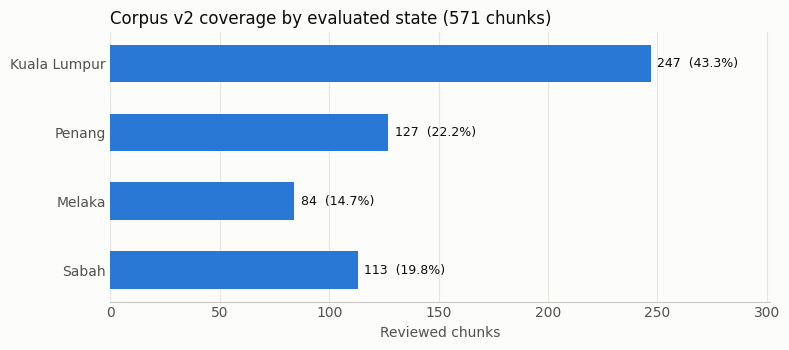

In [ ]:
import matplotlib.pyplot as plt
STATES = ['Kuala Lumpur', 'Penang', 'Melaka', 'Sabah']
TOPICS = {
    'Heritage & culture': r'(?i)\b(heritage|temple|mosque|church|colonial|historic|culture|cultural|museum|gallery)\b',
    'Food': r'(?i)\b(food|cuisine|dish|restaurant|hawker|nasi|satay|cafe|dining|eat)\b',
    'Nature & parks': r'(?i)\b(park|garden|forest|nature|lake|hill|waterfall|bird|island|beach|mount)\b',
    'Shopping': r'(?i)\b(shopping|mall|bazaar|market|boutique|retail)\b',
    'Opening hours stated': HOURS.pattern, 'Entry price stated': PRICE.pattern,
    'Disability access info': r'(?i)wheelchair|disabled|\boku\b|barrier-free|step-free',
}
rows = []
for s in STATES:
    docs = [d for d in unique_docs if d.metadata.get('state') == s]
    row = {'state': s, 'chunks': len(docs), 'share_%': round(len(docs) / len(unique_docs) * 100, 1),
           'with_page_ref': sum(d.metadata.get('page') is not None for d in docs)}
    for k, p in TOPICS.items():
        row[k] = sum(bool(re.search(p, d.page_content)) for d in docs)
    rows.append(row)
coverage = pd.DataFrame(rows)
print(coverage.to_string(index=False))
coverage.to_csv(BASE / 'docs' / 'week4_coverage_by_state.csv', index=False)

SERIES, INK, MUTED, SURFACE = '#2a78d6', '#0b0b0b', '#52514e', '#fcfcfb'
fig, ax = plt.subplots(figsize=(8, 3.6), facecolor=SURFACE); ax.set_facecolor(SURFACE)
order = coverage.iloc[::-1]
bars = ax.barh(order['state'], order['chunks'], height=0.55, color=SERIES)
for b, v, pct in zip(bars, order['chunks'], order['share_%']):
    ax.text(b.get_width() + 3, b.get_y() + b.get_height() / 2, f'{v}  ({pct}%)', va='center', fontsize=9, color=INK)
ax.set_xlabel('Reviewed chunks', color=MUTED)
ax.set_title(f'Corpus v2 coverage by evaluated state ({len(unique_docs)} chunks)', loc='left', color=INK)
ax.grid(axis='x', color='#e6e5e1', linewidth=0.8); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.spines['bottom'].set_color('#c9c8c3'); ax.tick_params(colors=MUTED, length=0)
ax.set_xlim(0, coverage['chunks'].max() * 1.22)
plt.tight_layout(); plt.savefig(BASE / 'docs' / 'week4_coverage_by_state.png', dpi=150); plt.show()


## 6 — Verify and download

In [ ]:
with open(BASE / 'data' / 'chunks_clean_v2.pkl', 'rb') as f:
    reloaded = pickle.load(f)
rows_v2 = [json.loads(l) for l in open(BASE / 'data' / 'prepared_chunks_clean_v2.jsonl', encoding='utf-8') if l.strip()]
assert len(reloaded) == len(rows_v2) and all(a['text'] == b.page_content for a, b in zip(rows_v2, reloaded))
print('PASS: corpus v2 PKL and JSONL match —', len(rows_v2), 'chunks')
print('Ligatures left:', sum(bool(LIGATURE.search(r['text'])) for r in rows_v2),
      '| glyph-ID left:', sum('/gid' in r['text'] for r in rows_v2))

manifest = {'created': str(date.today()), 'method': 'paragraph-aware-char-500 (+map-label-filter for map guides)',
            'sources': inspect_rows, 'removed': len(removed), 'new_chunks_kept': len(new_docs),
            'kl_chunks': len(kl_docs), 'corpus_v2_chunks': len(unique_docs),
            'outputs': {p: hashlib.sha256((BASE / p).read_bytes()).hexdigest()
                        for p in ['data/processed/prepared_text_states.jsonl', 'data/prepared_chunks_clean_v2.jsonl']}}
(BASE / 'data' / 'week4_states_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Saved data/week4_states_manifest.json')

OUT = ['data/processed/prepared_text_states.jsonl', 'data/prepared_chunks_clean_v2.jsonl', 'data/chunks_clean_v2.pkl',
       'data/week4_states_manifest.json', 'docs/week4_states_validation_failures.csv', 'docs/week4_states_quarantine_log.csv',
       'docs/week4_states_duplicate_review.csv', 'docs/week4_coverage_by_state.csv', 'docs/week4_coverage_by_state.png']
stage = BASE / 'week4b_download'
if stage.exists(): shutil.rmtree(stage)
for p in OUT:
    (stage / p).parent.mkdir(parents=True, exist_ok=True); shutil.copy(BASE / p, stage / p)
    print(f'{p:46} {os.path.getsize(BASE / p):>8} bytes')
archive = shutil.make_archive(str(BASE / 'week4b_outputs'), 'zip', stage)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Not in Colab — download', archive, 'manually.')


PASS: corpus v2 PKL and JSONL match — 571 chunks
Ligatures left: 0 | glyph-ID left: 0
Saved data/week4_states_manifest.json
data/processed/prepared_text_states.jsonl        197606 bytes
data/prepared_chunks_clean_v2.jsonl              474600 bytes
data/chunks_clean_v2.pkl                         449192 bytes
data/week4_states_manifest.json                    2244 bytes
docs/week4_states_validation_failures.csv          1323 bytes
docs/week4_states_quarantine_log.csv                603 bytes
docs/week4_states_duplicate_review.csv            49063 bytes
docs/week4_coverage_by_state.csv                    298 bytes
docs/week4_coverage_by_state.png                  41866 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>